# Business Entity Resolution — Amazon ML Challenge 2026

**Task.** For every Source1 (S1) business record, predict the set (possibly empty) of
Source2/Source3 (S2/S3) records that refer to the *same real-world business* — 0..n matches
per S1, but each S2/S3 record may be claimed by **at most one** S1 (1-to-1 on the pool side).

**Metric.** Macro-averaged F0.5 over all S1 rows, singletons included:

$$F_{0.5} = \frac{1.25 \cdot P \cdot R}{0.25 \cdot P + R} = \frac{1.25\,TP}{1.25\,TP + FP + 0.25\,FN}$$

Per S1: if truth is empty and prediction is empty → score **1.0**; empty truth + any prediction
→ **0.0**; non-empty truth + empty prediction → **0.0**; otherwise the F0.5 above. Final score is
the mean of this per-S1 score over all S1 rows (`ber.model.macro_f05`).

**Rules.** No external lookups, models capped at 8B params, MIT/Apache licensed only. Train = US + India;
**test adds a third, unseen country: France** — a genuine distribution shift. Data is heavily
multilingual: roughly 22% of S2 names are Indic-script phonetic transliterations of the *same*
underlying English business name, on top of accent noise, leet/web-junk noise and French addresses.

**Final (v4) pipeline:**

```
raw TSV (S1, S2, S3)
   | ber.text.prep_frame   two views (orig script / romanized); Indic transliteration (anusvara + schwa),
   |                       leet de-noising, web-junk stripping, leading-zero number normalization;
   |                       phonetic keys: name_key (consonant skeleton), name_key2 (coarse, voicing-blind), sorted keys
   v
 {split}_prep.parquet
   |  blocking, 6 kNN methods per country + key joins (ALL S1 blocked, incl. all 2.2M train S1)
   |    tfidf(name+addr) | tfidf(core name) | tfidf(skeleton key) | tfidf(coarse key) | tfidf(addr) | LaBSE exact top-k (GPU)
   |  hybrid cap: stage-0 LightGBM ranker top-60  U  each method's top-10  U  key hits   (~127 cand / S1)
   v
 {split}_feats_{0..7}.parquet   (~100 pair features, chunked by S1)
   |  stage 1: LightGBM, 2 OOF halves (each fit on 350k tr S1 ~ 44M rows), predicts every pair -> p1
   |  cross-encoder xlm-roberta-large fine-tuned on a disjoint 'ce' fold (5.07M pairs, stage-0 hard negatives),
   |            scored on pairs with p1 >= 0.005 -> ce
   |  stage 2: LightGBM on pairs with p1 >= 0.001 + ce + cluster-consistency (anchor) + p competition ranks -> p
   |  1-to-1 argmax over ALL S1, then threshold t=0.425 and relative margin alpha=0.7
   v
 matching_results.tsv  (submission)
```

Heavy compute (prep/embed/block/features/CE/train/predict at full scale) runs as PBS jobs on the HPC
cluster via `python -m ber.run <stage>` (see `../pbs/`). **This notebook does not run that compute.**
It explains the design, and visualizes artifacts the PBS jobs write to `WORK = ../working/v4`, plus a
small live demo on a cached sample.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # polars/sklearn deprecation + lightgbm chatter
import os, sys, json
os.environ["PYTHONWARNINGS"] = "ignore"  # also silences forked feature workers
from pathlib import Path

sys.path.insert(0, '../src')

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from ber import text as bt
from ber import block as bb
from ber import features as bf
from ber import model as bm

DATA = Path.home() / 'amazonml/amazon-ml/dataset'
WORK = Path('../working/v4')
SAMPLE = WORK / 'sample' if (WORK / 'sample').exists() else Path('../working/sample')
OUT = Path('../output')

sns.set_theme(style='whitegrid', context='notebook')
PALETTE = sns.color_palette('viridis', 8)

def style_ax(ax, title=None, xlabel=None, ylabel=None, logy=False):
    if title: ax.set_title(title, fontsize=12, weight='bold')
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    if logy: ax.set_yscale('log')
    ax.grid(alpha=0.3)
    return ax

def need(path, hint):
    ok = path.exists()
    if not ok:
        print(f"[missing] {path}  ->  run: {hint}")
    return ok

print('DATA =', DATA)
print('WORK =', WORK)
print('SAMPLE =', SAMPLE)

DATA = ~/amazonml/amazon-ml/dataset
WORK = ../working/v4
SAMPLE = ../working/sample


## 1. Data loading

Raw TSVs are read as **all-string columns** (`infer_schema=False`, `quote_char=None` — names
contain stray quote characters that would otherwise break CSV quoting) per the CONTRACT.
Ground truth is `source1_entity_id, matched_entity_ids` (comma-separated, may be empty/NaN).

- Observation: train S1/S2/S3 are 2,206,821 / 5,034,616 / 5,285,603 rows; test S1/S2/S3 are 1,732,544 / 4,887,273 / 5,082,316 rows; train ground truth has 2,206,821 rows (one per S1). All frames load cleanly as 4-column, all-string tables — no dtype surprises.

In [2]:
def read_tsv(p):
    return pl.read_csv(p, separator='\t', quote_char=None, infer_schema=False,
                        empty_string_is_null=False)

shapes = []
frames = {}
for split in ('train', 'test'):
    for s in (1, 2, 3):
        p = DATA / split / f'{split}_source{s}.tsv'
        if not need(p, f'(raw data — should already exist under $BER_DATA)'):
            continue
        df = read_tsv(p)
        frames[(split, s)] = df
        shapes.append({'split': split, 'source': f'S{s}', 'rows': df.height, 'cols': df.width})

gt_path = DATA / 'train/train_ground_truth.tsv'
if need(gt_path, '(raw data)'):
    gt_raw = read_tsv(gt_path)
    shapes.append({'split': 'train', 'source': 'ground_truth', 'rows': gt_raw.height, 'cols': gt_raw.width})

shapes_df = pl.DataFrame(shapes)
shapes_df

split,source,rows,cols
str,str,i64,i64
"""train""","""S1""",2206821,4
"""train""","""S2""",5034616,4
"""train""","""S3""",5285603,4
"""test""","""S1""",1732544,4
"""test""","""S2""",4887273,4
"""test""","""S3""",5082316,4
"""train""","""ground_truth""",2206821,2


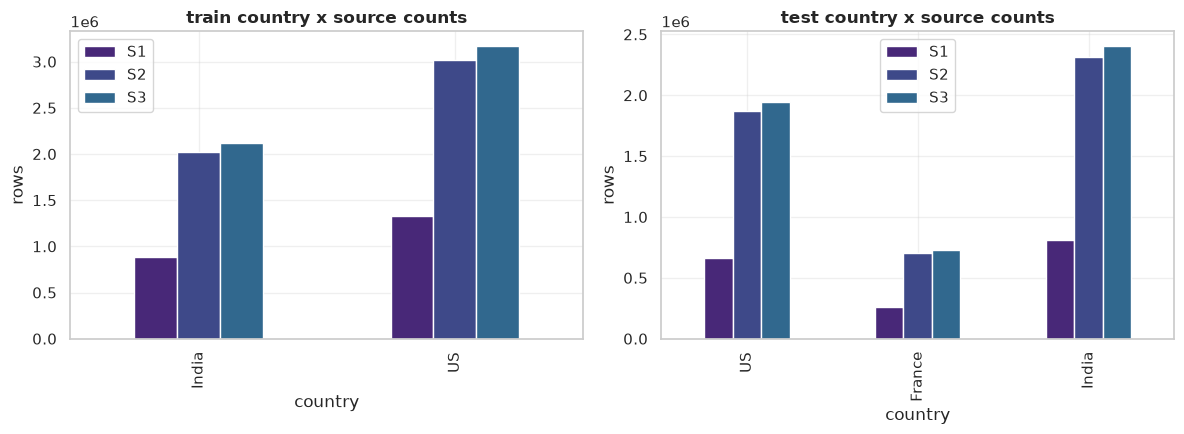

In [3]:
# country mix per split/source
country_mix = []
for (split, s), df in frames.items():
    if 'country' not in df.columns:
        continue
    vc = df['country'].value_counts().rename({'count': 'n'})
    for row in vc.iter_rows(named=True):
        country_mix.append({'split': split, 'source': f'S{s}', 'country': row['country'], 'n': row['n']})
cm = pl.DataFrame(country_mix)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
for ax, split in zip(axes, ('train', 'test')):
    sub = cm.filter(pl.col('split') == split)
    piv = sub.pivot(index='country', on='source', values='n').fill_null(0)
    piv_pd = piv.to_pandas().set_index('country')
    piv_pd.plot(kind='bar', ax=ax, color=PALETTE[:piv_pd.shape[1]])
    style_ax(ax, title=f'{split} country x source counts', xlabel='country', ylabel='rows')
plt.tight_layout()
plt.show()

Note: the largest artifacts here are the S2/S3 pools (millions of rows across train+test) held
as all-`Utf8` polars frames — comfortably fits in a laptop's memory for EDA at this stage since
we read a small sample / the raw TSVs directly, but full `{split}_prep.parquet` with romanized
+ skeleton columns roughly doubles the string payload; that step runs on the HPC box, not here.

## 2. Exploratory data analysis

Ground-truth cardinality, singleton share, S2-vs-S3 split of true matches, distractor share of
the pool, length distributions, token frequencies, missing/placeholder values, **script
distribution** (the core multilingual challenge), cross-script true-pair rate, a noise-type
example gallery, postcode/number agreement in true vs random pairs, and a France test profile.

S1 rows: 2,206,821 | with >=1 match: 2,083,574 | singletons: 123,247 (5.6%)


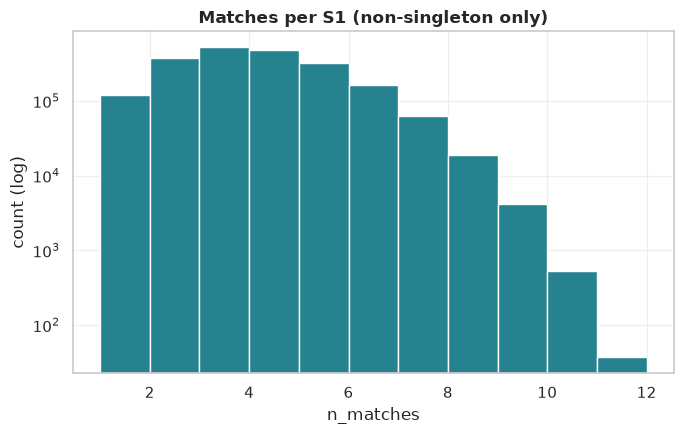

In [4]:
# ground truth cardinality
gt_exp = (gt_raw
    .with_columns(pl.col('matched_entity_ids').str.split(','))
    .explode('matched_entity_ids')
)
gt_matches = gt_exp.filter(pl.col('matched_entity_ids') != '')
card = gt_matches.group_by('source1_entity_id').agg(pl.len().alias('n_matches'))
n_s1 = gt_raw.height
n_singleton = n_s1 - card.height  # S1 rows with zero matches (absent from exploded matches)
singleton_share = n_singleton / n_s1
print(f'S1 rows: {n_s1:,} | with >=1 match: {card.height:,} | singletons: {n_singleton:,} ({singleton_share:.1%})')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(card['n_matches'].to_list(), bins=range(1, card['n_matches'].max() + 2),
        color=PALETTE[3], edgecolor='white')
style_ax(ax, title='Matches per S1 (non-singleton only)', xlabel='n_matches', ylabel='count (log)', logy=True)
plt.tight_layout()
plt.show()

In [5]:
# S2 vs S3 share of true matches
s2_ids = set(frames[('train', 2)]['entity_id'].to_list())
s3_ids = set(frames[('train', 3)]['entity_id'].to_list())
m_ids = gt_matches['matched_entity_ids'].to_list()
n_s2 = sum(1 for x in m_ids if x in s2_ids)
n_s3 = sum(1 for x in m_ids if x in s3_ids)
print(f'true matches from S2: {n_s2:,} ({n_s2/(n_s2+n_s3):.1%}) | from S3: {n_s3:,} ({n_s3/(n_s2+n_s3):.1%})')

# distractor share: pool records never matched
matched_set = set(m_ids)
for s in (2, 3):
    pool_ids = set(frames[('train', s)]['entity_id'].to_list())
    distractors = pool_ids - matched_set
    print(f'S{s}: pool={len(pool_ids):,} matched={len(pool_ids & matched_set):,} '
          f'distractors={len(distractors):,} ({len(distractors)/len(pool_ids):.1%})')

true matches from S2: 3,693,619 (48.4%) | from S3: 3,944,746 (51.6%)


S2: pool=5,034,616 matched=3,693,619 distractors=1,340,997 (26.6%)


S3: pool=5,285,603 matched=3,944,746 distractors=1,340,857 (25.4%)


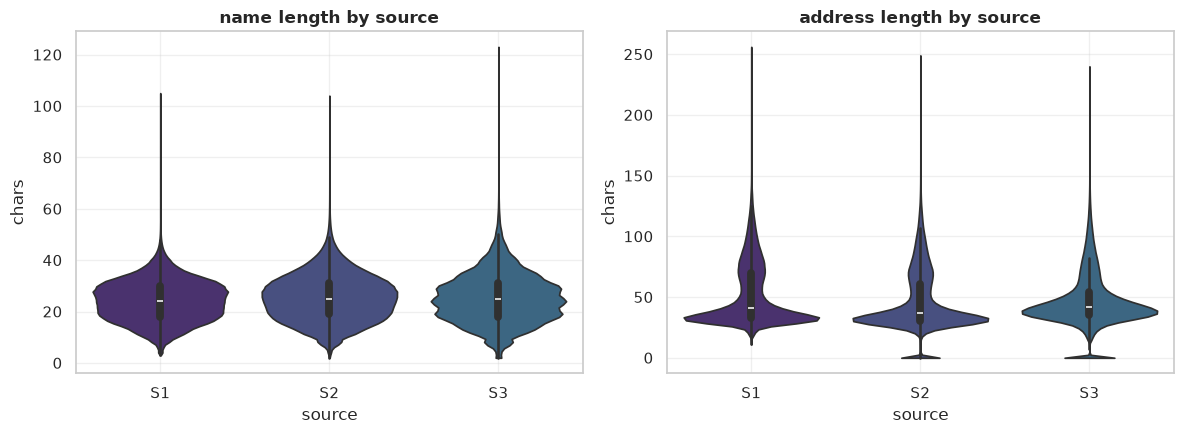

In [6]:
# name / address length distributions by source (train)
len_rows = []
for s in (1, 2, 3):
    df = frames[('train', s)]
    for col, kind in (('business_name', 'name'), ('business_address', 'address')):
        lens = df[col].fill_null('').str.len_chars().to_list()
        len_rows.extend({'source': f'S{s}', 'field': kind, 'len': l} for l in lens)
len_df = pl.DataFrame(len_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, field in zip(axes, ('name', 'address')):
    sub = len_df.filter(pl.col('field') == field).to_pandas()
    sns.violinplot(data=sub, x='source', y='len', ax=ax, palette=PALETTE, cut=0)
    style_ax(ax, title=f'{field} length by source', xlabel='source', ylabel='chars')
plt.tight_layout()
plt.show()

In [7]:
# top-30 tokens per country (S1 names, train), crude whitespace tokenization on raw text
def top_tokens(df, col, n=30):
    toks = (df.select(pl.col(col).fill_null('').str.to_lowercase()
                        .str.split(' ').alias('t'))
              .explode('t').filter(pl.col('t').str.len_chars() > 1))
    return toks['t'].value_counts().sort('count', descending=True).head(n)

for country in frames[('train', 1)]['country'].unique().to_list()[:3]:
    sub = frames[('train', 1)].filter(pl.col('country') == country)
    tt = top_tokens(sub, 'business_name')
    print(f'--- {country} top tokens ---')
    print(tt)

--- US top tokens ---
shape: (30, 2)
┌────────────┬────────┐
│ t          ┆ count  │
│ ---        ┆ ---    │
│ str        ┆ u32    │
╞════════════╪════════╡
│ llc        ┆ 355725 │
│ inc        ┆ 190225 │
│ and        ┆ 57288  │
│ inc.       ┆ 48083  │
│ care       ┆ 41375  │
│ …          ┆ …      │
│ physicians ┆ 10040  │
│ regional   ┆ 8740   │
│ blue       ┆ 8666   │
│ co         ┆ 8279   │
│ holdings   ┆ 8237   │
└────────────┴────────┘


--- India top tokens ---
shape: (30, 2)
┌───────────┬────────┐
│ t         ┆ count  │
│ ---       ┆ ---    │
│ str       ┆ u32    │
╞═══════════╪════════╡
│ limited   ┆ 521781 │
│ private   ┆ 431858 │
│ ltd       ┆ 119400 │
│ pvt       ┆ 94922  │
│ (india)   ┆ 43993  │
│ …         ┆ …      │
│ ventures  ┆ 11534  │
│ traders   ┆ 11356  │
│ care      ┆ 11047  │
│ marketing ┆ 10989  │
│ sons      ┆ 10717  │
└───────────┴────────┘


In [8]:
# missing / placeholder values
PLACEHOLDERS = {'', 'null', 'n/a', 'na', 'none', 'nil'}
miss_rows = []
for (split, s), df in frames.items():
    for col in ('business_name', 'business_address'):
        if col not in df.columns:
            continue
        vals = df[col].fill_null('').str.to_lowercase().str.strip_chars()
        n_missing = vals.is_in(list(PLACEHOLDERS)).sum()
        miss_rows.append({'split': split, 'source': f'S{s}', 'field': col,
                           'n_missing_or_placeholder': n_missing, 'pct': n_missing / df.height})
pl.DataFrame(miss_rows)

split,source,field,n_missing_or_placeholder,pct
str,str,str,i64,f64
"""train""","""S1""","""business_name""",0,0.0
"""train""","""S1""","""business_address""",0,0.0
"""train""","""S2""","""business_name""",5,9.9312e-7
"""train""","""S2""","""business_address""",168967,0.033561
"""train""","""S3""","""business_name""",18,0.000003
…,…,…,…,…
"""test""","""S1""","""business_address""",0,0.0
"""test""","""S2""","""business_name""",49,0.00001
"""test""","""S2""","""business_address""",129408,0.026479


### Script analysis

The task's central difficulty: S2 names are frequently phonetic transliterations of the S1
English name into an Indic script. `ber.text.script_of` gives the dominant Unicode-block script
of a raw string; we sample up to 300k rows per source (full frames are small enough here that
sampling is mostly for speed of the python-side apply, not memory).

In [9]:
import random
random.seed(0)

def sample_scripts(df, col, cap=300_000):
    vals = df[col].fill_null('').to_list()
    if len(vals) > cap:
        vals = random.sample(vals, cap)
    return [bt.script_of(v) for v in vals]

script_rows = []
for (split, s), df in frames.items():
    if split != 'train':
        continue
    scripts = sample_scripts(df, 'business_name')
    countries = df['country'].fill_null('?').to_list()
    countries = countries[:len(scripts)] if len(scripts) < df.height else countries
    for sc, c in zip(scripts, countries):
        script_rows.append({'source': f'S{s}', 'country': c, 'script': sc})
script_df = pl.DataFrame(script_rows)

# share of non-latin per source
for s in ('S1', 'S2', 'S3'):
    sub = script_df.filter(pl.col('source') == s)
    nonlatin = (sub['script'] != 'latin').mean()
    print(f'{s}: non-latin script share = {nonlatin:.1%}')

S1: non-latin script share = 0.0%
S2: non-latin script share = 9.2%
S3: non-latin script share = 5.0%


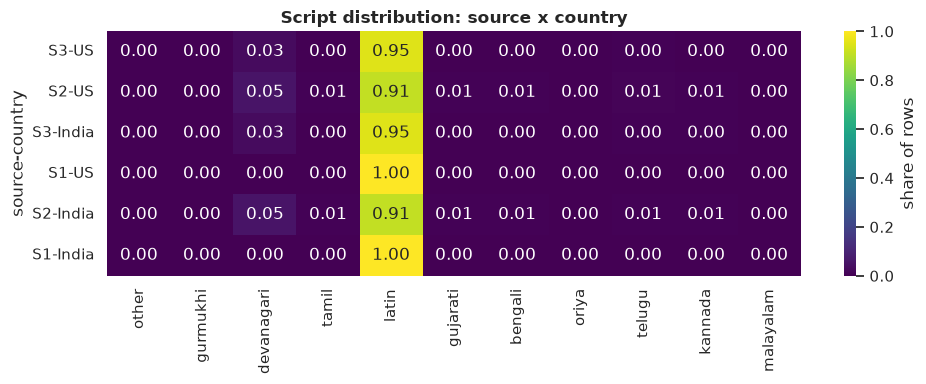

In [10]:
piv = (script_df.group_by(['source', 'country', 'script']).agg(pl.len().alias('n'))
                 .pivot(index=['source', 'country'], on='script', values='n').fill_null(0))
piv_pd = piv.to_pandas().set_index(['source', 'country'])
piv_frac = piv_pd.div(piv_pd.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(piv_frac))))
sns.heatmap(piv_frac, cmap='viridis', annot=True, fmt='.2f', cbar_kws={'label': 'share of rows'}, ax=ax)
style_ax(ax, title='Script distribution: source x country')
plt.tight_layout()
plt.show()

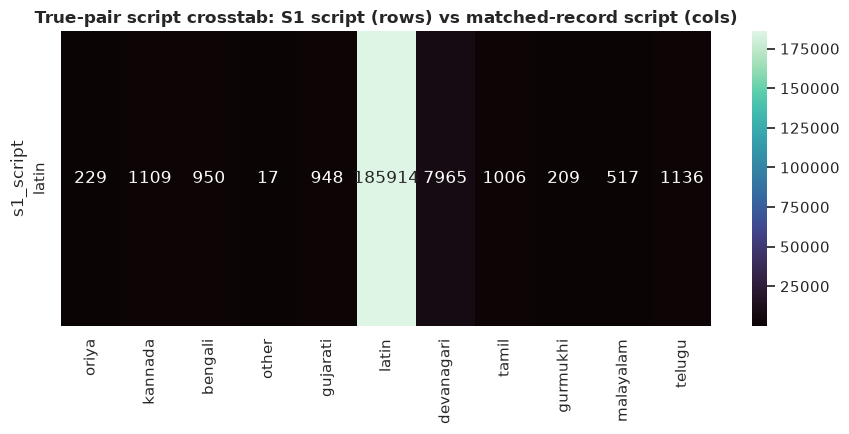

cross-script true-pair rate (sample): 7.0%


In [11]:
# cross-script true-pair rate: S1 script vs matched-record script, on a sample of GT
gt_pairs = gt_matches.rename({'source1_entity_id': 's1_id', 'matched_entity_ids': 'c_id'})
if gt_pairs.height > 200_000:
    gt_pairs = gt_pairs.sample(200_000, seed=0)

s1_script = (frames[('train', 1)].select(pl.col('entity_id').alias('s1_id'),
                                          pl.col('business_name').alias('s1_name')))
pool_script = pl.concat([
    frames[('train', 2)].select(pl.col('entity_id').alias('c_id'), pl.col('business_name').alias('c_name')),
    frames[('train', 3)].select(pl.col('entity_id').alias('c_id'), pl.col('business_name').alias('c_name')),
])

joined = gt_pairs.join(s1_script, on='s1_id', how='inner').join(pool_script, on='c_id', how='inner')
joined = joined.with_columns(
    pl.col('s1_name').map_elements(bt.script_of, return_dtype=pl.Utf8).alias('s1_script'),
    pl.col('c_name').map_elements(bt.script_of, return_dtype=pl.Utf8).alias('c_script'),
)
cross_tab = joined.group_by(['s1_script', 'c_script']).agg(pl.len().alias('n')).pivot(
    index='s1_script', on='c_script', values='n').fill_null(0)

fig, ax = plt.subplots(figsize=(9, 4.5))
cross_pd = cross_tab.to_pandas().set_index('s1_script')
sns.heatmap(cross_pd, cmap='mako', annot=True, fmt='d', ax=ax)
style_ax(ax, title='True-pair script crosstab: S1 script (rows) vs matched-record script (cols)')
plt.tight_layout()
plt.show()

cross_script_rate = 1 - (joined['s1_script'] == joined['c_script']).mean()
print(f'cross-script true-pair rate (sample): {cross_script_rate:.1%}')

### Example gallery: noise types in true pairs

Programmatically pick a few true pairs illustrating each noise type: a cross-script pair
(transliteration), a pair where postcode disagrees (address noise / stale postcode), and a
couple of arbitrary same-script pairs for contrast (abbreviation / word-order / accent noise
show up naturally once normalized — see Section 3).

- Observation: cross-script examples show the S1 Latin name reappearing as a Devanagari/Kannada transliteration in S2/S3 (e.g. "Hotel Ventures Limited" vs "होटल वेंचर्स लिमिटेड") while the address stays largely aligned; postcode-mismatch examples are mostly formatting noise (leading zeros, stray '#') rather than a genuinely different postcode. Measured postcode agreement: 90.4% on true pairs vs 0.0% on random pairs, confirming postcode is a strong (if noisy) signal.

In [12]:
addr_lookup = {}
for s in (1, 2, 3):
    addr_lookup[s] = dict(zip(frames[('train', s)]['entity_id'], frames[('train', s)]['business_address']))
name_lookup = {1: dict(zip(frames[('train', 1)]['entity_id'], frames[('train', 1)]['business_name']))}
name_lookup[2] = dict(zip(frames[('train', 2)]['entity_id'], frames[('train', 2)]['business_name']))
name_lookup[3] = dict(zip(frames[('train', 3)]['entity_id'], frames[('train', 3)]['business_name']))
pc_lookup = {}
for s in (1, 2, 3):
    pc_lookup[s] = {eid: bt.parse_address(a or '')['postcode']
                     for eid, a in zip(frames[('train', s)]['entity_id'], frames[('train', s)]['business_address'])}
src_of = {}
for s in (2, 3):
    for eid in frames[('train', s)]['entity_id'].to_list():
        src_of[eid] = s

cross_script_examples = joined.filter(pl.col('s1_script') != pl.col('c_script')).head(4)
postcode_diff_examples = []
for row in gt_pairs.head(20000).iter_rows(named=True):
    s1id, cid = row['s1_id'], row['c_id']
    csrc = src_of.get(cid)
    if csrc is None:
        continue
    p1, p2 = pc_lookup[1].get(s1id, ''), pc_lookup[csrc].get(cid, '')
    if p1 and p2 and p1 != p2:
        postcode_diff_examples.append((s1id, cid, csrc))
    if len(postcode_diff_examples) >= 4:
        break

gallery = []
for row in cross_script_examples.iter_rows(named=True):
    s1id, cid = row['s1_id'], row['c_id']
    csrc = src_of.get(cid, 2)
    gallery.append({'type': 'cross-script', 's1_name': name_lookup[1].get(s1id, ''),
                     'c_name': name_lookup[csrc].get(cid, ''), 's1_addr': addr_lookup[1].get(s1id, ''),
                     'c_addr': addr_lookup[csrc].get(cid, '')})
for s1id, cid, csrc in postcode_diff_examples:
    gallery.append({'type': 'postcode-mismatch', 's1_name': name_lookup[1].get(s1id, ''),
                     'c_name': name_lookup[csrc].get(cid, ''), 's1_addr': addr_lookup[1].get(s1id, ''),
                     'c_addr': addr_lookup[csrc].get(cid, '')})

pl.DataFrame(gallery)

type,s1_name,c_name,s1_addr,c_addr
str,str,str,str,str
"""cross-script""","""Hotel Ventures Limited""","""होटल वेंचर्स लिमिटेड""","""C-121, Meena Bakery Chauraha N…","""LUCKNOW, C-121, MEENA BAKERY C…"
"""cross-script""","""Real First Trading Limited""","""रियल First ट्रेडिंग Limited""","""R-45, Advocate Colony, Pratap …","""R-#45, ADVOCATE COLONY, PRATAP…"
"""cross-script""","""Perfect Constructions Limited""","""ಪರ್ಫೆಕ್ಟ್ ಕನ್‌ಸ್ಟ್ರಕ್ಷನ್ಸ್ ಲಿಮ…","""Millers Road, Benson Town, Nan…","""Karnataka, MILLERS ROAD, BENSO…"
"""cross-script""","""Bharat Technologies Private Li…","""भारत टेक्नोलॉजीज प्राइवेट लिमि…","""Flat No. 403, House No. 204/A …","""HOUSE NO. 204/A AND 204/B RANJ…"
"""postcode-mismatch""","""Quality Renaissancere Inc""","""QR""","""15526 Zion Hill Road, Andalusi…","""015526 ZION HILL RD, ANDALUSIA…"
"""postcode-mismatch""","""Clean Aberdeen P.C.""","""Clean Aefndn P.C.""","""13023 Roxboro Road, Durham, NC""","""13235 ROXBORO RD, DURHAM, NC"""
"""postcode-mismatch""","""Stewart Wisconsin Inc.""","""Stewart Inc. Wisconsin""","""12010 Maryland Manor Drive, Ma…","""12010-12012 Maryland Manor Dr,…"
"""postcode-mismatch""","""Dusty Gray General Center""","""Dusty Gray General Center Co""","""17314 430th Avenue, North Bend…","""##17170 430TH AVE, NORTH BEND,…"


In [13]:
# postcode / number agreement rate: true pairs vs random pairs (same-country)
def postcode_agree_rate(pairs_iter, cap=20000):
    agree, total = 0, 0
    for s1id, cid, csrc in pairs_iter:
        p1, p2 = pc_lookup[1].get(s1id, ''), pc_lookup[csrc].get(cid, '')
        if not p1 or not p2:
            continue
        total += 1
        agree += (p1 == p2)
        if total >= cap:
            break
    return agree / total if total else float('nan')

true_iter = ((r['s1_id'], r['c_id'], src_of.get(r['c_id'], 2)) for r in gt_pairs.iter_rows(named=True) if r['c_id'] in src_of)
true_rate = postcode_agree_rate(true_iter)

random.seed(1)
s1_ids_all = frames[('train', 1)]['entity_id'].to_list()
pool_all = frames[('train', 2)]['entity_id'].to_list() + frames[('train', 3)]['entity_id'].to_list()
random_iter = ((random.choice(s1_ids_all), cid, src_of.get(cid, 2))
               for cid in random.sample(pool_all, min(20000, len(pool_all))))
random_rate = postcode_agree_rate(random_iter)

print(f'postcode agreement — true pairs: {true_rate:.1%} | random pairs: {random_rate:.1%}')

postcode agreement — true pairs: 90.4% | random pairs: 0.0%


### France test profile

Train never sees France. Compare France's top tokens, legal-form counts (SARL/SAS/EURL/...),
and street-type prefixes (rue/avenue/boulevard) against India/US to see how different the
unseen-country distribution shift actually is.

In [14]:
if need(DATA / 'test/test_source1.tsv', 'ber.run prep --split test (upstream: raw data present)'):
    test_s1 = read_tsv(DATA / 'test/test_source1.tsv')
    fr = test_s1.filter(pl.col('country').str.to_lowercase().str.contains('fr'))
    print('France S1 rows:', fr.height, '| countries seen in test:', test_s1['country'].unique().to_list())

    print('--- France top tokens ---')
    print(top_tokens(fr, 'business_name', n=15))

    LEGAL_FORMS = ['sarl', 'sas', 'eurl', 'sasu', 'sci', 'snc']
    STREET_TYPES = ['rue', 'avenue', 'boulevard', 'chemin', 'impasse']
    fr_name_low = fr['business_name'].fill_null('').str.to_lowercase()
    fr_addr_low = fr['business_address'].fill_null('').str.to_lowercase()
    for lf in LEGAL_FORMS:
        print(f'  legal form "{lf}": {fr_name_low.str.contains(lf).sum()}')
    for st in STREET_TYPES:
        print(f'  street type "{st}": {fr_addr_low.str.contains(st).sum()}')

France S1 rows: 259452 | countries seen in test: ['France', 'India', 'US']
--- France top tokens ---
shape: (15, 2)
┌──────────┬───────┐
│ t        ┆ count │
│ ---      ┆ ---   │
│ str      ┆ u32   │
╞══════════╪═══════╡
│ sarl     ┆ 73449 │
│ sas      ┆ 52254 │
│ club     ┆ 22668 │
│ (france) ┆ 20792 │
│ eurl     ┆ 16968 │
│ …        ┆ …     │
│ du       ┆ 10728 │
│ sasu     ┆ 10712 │
│ centre   ┆ 10500 │
│ comite   ┆ 9953  │
│ union    ┆ 8627  │
└──────────┴───────┘


  legal form "sarl": 73486
  legal form "sas": 63019
  legal form "eurl": 16980
  legal form "sasu": 10721
  legal form "sci": 8559
  legal form "snc": 11
  street type "rue": 170928
  street type "avenue": 30988
  street type "boulevard": 9310
  street type "chemin": 3690
  street type "impasse": 5134


## 3. Preprocessing — `ber.text.normalize_record`

Demonstrated on hand-picked realistic examples spanning: Devanagari transliteration, an
abbreviated Hindi legal form ("प्रा. लि." → `pvt ltd`), a French `SASU` suffix, a French street
address, accent noise, and an India-style multi-line address.

In [15]:
examples = [
    ('रियल मॉडर्न फूड लिमिटेड', None),
    ('ड्रीम आईटी प्रा. लि.', None),
    ('Real Modern Food Limited', None),
    ('Thermal & Fils SASU', None),
    (None, '63 R. DE DIEPPE, LILLE'),
    ('Animal Welfare Nétwork', None),
    (None, 'Maharashtra, Mumbai, A-46, Kondivita Road, Andheri (East) 400059'),
    ('বোম্বে ইনভেস্টমেন্ট এলএলপি', None),
    ('Bombay Investment LLP', None),
    ('SARL Dupont & Fils', '12 Rue de la Paix, 75002 Paris'),
    ('Sólar Energy Pvt. Ltd.', None),
    ('N/A', 'Main St'),
]

rows = []
for name, addr in examples:
    rec = bt.normalize_record(name, addr)
    rows.append({'name_in': name, 'addr_in': addr, **rec})
demo_df = pl.DataFrame(rows)
demo_df.select('name_in', 'addr_in', 'name', 'addr', 'core', 'legal', 'name_key', 'postcode', 'script')

name_in,addr_in,name,addr,core,legal,name_key,postcode,script
str,str,str,str,str,str,str,str,str
"""रियल मॉडर्न फूड लिमिटेड""",null,"""riyal modarn phud limited""","""""","""riyal modarn phud""","""ltd""","""rl mdrn fd lmtd""","""""","""devanagari"""
"""ड्रीम आईटी प्रा. लि.""",null,"""drim aiti pra li""","""""","""drim aiti""","""pvt ltd""","""drm at pr l""","""""","""devanagari"""
"""Real Modern Food Limited""",null,"""real modern food limited""","""""","""real modern food""","""ltd""","""rl mdrn fd lmtd""","""""","""latin"""
"""Thermal & Fils SASU""",null,"""thermal fils sasu""","""""","""thermal fils""","""sasu""","""trml fls ss""","""""","""latin"""
null,"""63 R. DE DIEPPE, LILLE""","""""","""63 rue de dieppe lille""","""""","""""","""""","""""","""other"""
…,…,…,…,…,…,…,…,…
"""বোম্বে ইনভেস্টমেন্ট এলএলপি""",null,"""vomve inabhestament elaelapi""","""""","""vomve inabhestament""","""llp""","""bnb anbstmnt allp""","""""","""bengali"""
"""Bombay Investment LLP""",null,"""bombay investment llp""","""""","""bombay investment""","""llp""","""bnb anbstmnt llp""","""""","""latin"""
"""SARL Dupont & Fils""","""12 Rue de la Paix, 75002 Paris""","""sarl dupont fils""","""12 rue de la paix 75002 paris""","""sarl dupont fils""","""""","""srl dpnt fls""","""75002""","""latin"""


In [16]:
# skeleton key equality across scripts (cross-script bridge)
hi = bt.normalize_record('रियल मॉडर्न फूड लिमिटेड', None)
en = bt.normalize_record('Real Modern Food Limited', None)
print('devanagari name_key:', hi['name_key'])
print('english   name_key:', en['name_key'])
print('equal:', hi['name_key'] == en['name_key'])

devanagari name_key: rl mdrn fd lmtd
english   name_key: rl mdrn fd lmtd
equal: True


name_key exact-equal share (normalized): 31.6%  (n=50,000)


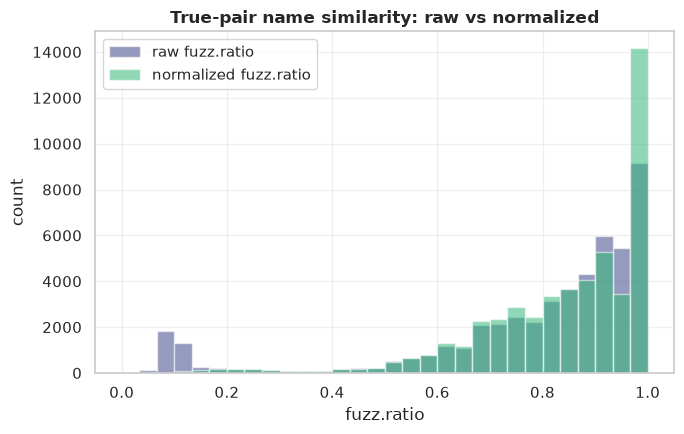

In [17]:
# measure: fuzz.ratio raw vs normalized, on a sample of true pairs (romanized name only)
from rapidfuzz import fuzz

sample_pairs = gt_pairs.filter(pl.col('c_id').is_in(list(src_of.keys()))).sample(
    min(50_000, gt_pairs.height), seed=0)

raw_ratios, norm_ratios, key_eq = [], [], []
for row in sample_pairs.iter_rows(named=True):
    s1id, cid = row['s1_id'], row['c_id']
    csrc = src_of[cid]
    n1, n2 = name_lookup[1].get(s1id, '') or '', name_lookup[csrc].get(cid, '') or ''
    raw_ratios.append(fuzz.ratio(n1.lower(), n2.lower()) / 100.0)
    r1, r2 = bt.normalize_record(n1, None), bt.normalize_record(n2, None)
    norm_ratios.append(fuzz.ratio(r1['name'], r2['name']) / 100.0)
    key_eq.append(r1['name_key'] == r2['name_key'] and r1['name_key'] != '')

print(f'name_key exact-equal share (normalized): {np.mean(key_eq):.1%}  (n={len(key_eq):,})')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(raw_ratios, bins=30, alpha=0.55, label='raw fuzz.ratio', color=PALETTE[1])
ax.hist(norm_ratios, bins=30, alpha=0.55, label='normalized fuzz.ratio', color=PALETTE[5])
ax.legend()
style_ax(ax, title='True-pair name similarity: raw vs normalized', xlabel='fuzz.ratio', ylabel='count')
plt.tight_layout()
plt.show()

## 4. Blocking — `ber.block`

Six kNN methods run **per country**, plus exact key joins; their union has pair recall **~0.983** on
the val S1 fold:

- **`tfidf_knn`** (char n-gram TF-IDF cosine) over five views: romanized `name+addr`, `core` (legal
  suffix stripped), the consonant-skeleton `name_key`, the coarse voicing-blind `name_key2`
  (Tamil has no t/d, k/g, p/b distinction, so those collapse to one sound class), and `addr`.
- **`emb_knn`** — LaBSE embedding exact top-k on GPU over the **original-script** `name_orig | addr_orig`;
  recovers Indic-script strings that share almost no character n-grams with their Latin transliteration.
- **`key_block`** — exact joins on postcode and on phonetic-key tokens (group size capped).

**Hybrid cap** (`learned_cap`): a stage-0 LightGBM ranker keeps the top-60 per S1, united with every
method's top-10 and all key hits (hard pairs look like non-matches on raw similarities, so a pure
learned cap drops them) — recall **0.9803** at ~**127 candidates/S1**.

**All 2.2M train S1 are blocked**, not just the fold S1, so pool-side competition matches test. An earlier
version blocked only the fold S1, giving ~5 S1 per pool record vs ~22 in test — a train/test skew in the
`rank_c` / `n_cands_c` features.

Recall is measured against ground truth with `ber.block.recall_report`; `blocking_report.json`
covers the val S1 fold only.

(val S1 fold only)
pair_recall: 0.9802761113118902
frac_s1_fully_covered: 0.9377693994048061
mean/median candidates per S1: 126.72786 127.0


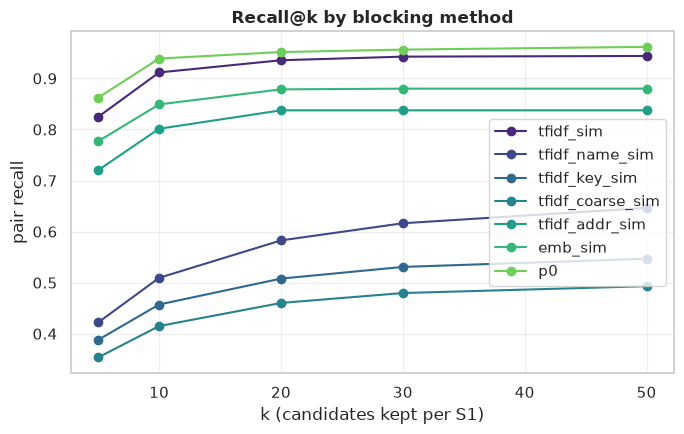

In [18]:
report_path = WORK / 'blocking_report.json'
if need(report_path, 'python -m ber.run features:train  (writes blocking_report.json)'):
    rep = json.loads(report_path.read_text())
    print('(val S1 fold only)')
    print('pair_recall:', rep['pair_recall'])
    print('frac_s1_fully_covered:', rep['frac_s1_fully_covered'])
    print('mean/median candidates per S1:', rep['mean_cand_per_s1'], rep['median_cand_per_s1'])

    fig, ax = plt.subplots(figsize=(7, 4.5))
    for i, (col, curve) in enumerate(rep['recall_at_k'].items()):
        ks = sorted(int(k) for k in curve.keys())
        vals = [curve[str(k)] for k in ks]
        ax.plot(ks, vals, marker='o', label=col, color=PALETTE[i])
    ax.legend()
    style_ax(ax, title='Recall@k by blocking method', xlabel='k (candidates kept per S1)', ylabel='pair recall')
    plt.tight_layout()
    plt.show()

In [19]:
# pairs/S1 and reduction ratio vs full cross product, per country.
# Uses p1_train.parquet = the capped candidate set the models actually score (3 narrow columns);
# re-unioning the raw blocking files over 2.2M S1 is a ~480M-row outer join (the pipeline chunks it).
cand_path = WORK / 'p1_train.parquet'
if need(cand_path, 'python -m ber.run train1'):
    pairs_all = pl.read_parquet(cand_path, columns=['s1_idx', 'c_idx'])
    prep_train = pl.read_parquet(WORK / 'train_prep.parquet') if (WORK / 'train_prep.parquet').exists() else None
    if prep_train is not None:
        cnt = prep_train.group_by('country').agg(
            (pl.col('src') == 1).sum().alias('n_s1'),
            (pl.col('src') != 1).sum().alias('n_pool'),
        )
        joined_pairs = pairs_all.join(
            prep_train.select(pl.col('idx').alias('s1_idx'), pl.col('country')), on='s1_idx')
        pairs_per_country = joined_pairs.group_by('country').agg(pl.len().alias('n_pairs'))
        red = cnt.join(pairs_per_country, on='country', how='left').with_columns(
            (pl.col('n_s1') * pl.col('n_pool')).alias('full_cross'),
        ).with_columns(
            (pl.col('n_pairs') / pl.col('n_s1')).alias('pairs_per_s1'),
            (1 - pl.col('n_pairs') / pl.col('full_cross')).alias('reduction_ratio'),
        )
        red
else:
    print('[missing] train_blk_*.parquet -> run: python -m ber.run block:train blockgpu:train')

### Live demo on a cached local sample

`ber.run stage_sample` (`python -m ber.run sample --n 20000`) writes a small, real-data replica
under `$BER_WORK/sample/{train,test}` — the true matches plus ~50% distractor noise per pool
source, small enough to block locally with modest `n_jobs` (no GPU / no PBS needed) as a sanity
check of the blocking code path.

In [20]:
if SAMPLE.exists():
    sample_prep_path = SAMPLE / 'train_prep_demo.parquet'
    s1_df = read_tsv(SAMPLE / 'train' / 'train_source1.tsv').with_columns(pl.lit(1, pl.Int8).alias('src'))
    s2_df = read_tsv(SAMPLE / 'train' / 'train_source2.tsv').with_columns(pl.lit(2, pl.Int8).alias('src'))
    s3_df = read_tsv(SAMPLE / 'train' / 'train_source3.tsv').with_columns(pl.lit(3, pl.Int8).alias('src'))
    raw_sample = pl.concat([s1_df, s2_df, s3_df])
    prep_sample = bt.prep_frame(raw_sample, n_jobs=2).with_row_index('idx').with_columns(pl.col('idx').cast(pl.Int32))

    t = bb.tfidf_knn(prep_sample, ['name', 'addr'], k=10, n_jobs=2)
    tc = bb.tfidf_knn(prep_sample, ['name_key2'], k=10, n_jobs=2, name='tfidf_coarse_sim', ngram_range=(2, 4))
    kb = bb.key_block(prep_sample)
    # cap_pairs = rank-fusion cap (no stage-0 model in the demo; production uses block.learned_cap)
    demo_pairs = bb.cap_pairs(bb.union_pairs(t, tc, kb), 60, per_method=10)
    print('demo candidate pairs:', demo_pairs.height)

    # build GT via polars joins (mirrors ber.run.stage_prep) instead of per-row dict lookups —
    # some matched ids aren't present in prep/dups, which made the two id-mapped columns
    # come out different lengths when built independently
    gt_sample = read_tsv(SAMPLE / 'train' / 'train_ground_truth.tsv')
    key = prep_sample.select('entity_id', 'idx')
    gt_exp_s = (gt_sample.with_columns(pl.col('matched_entity_ids').str.split(','))
                          .explode('matched_entity_ids', empty_as_null=True)
                          .with_columns(pl.col('matched_entity_ids').str.strip_chars('" ')))
    gt_sample_idx = (gt_exp_s.join(key, left_on='source1_entity_id', right_on='entity_id')
                              .join(key, left_on='matched_entity_ids', right_on='entity_id', suffix='_c')
                              .select(pl.col('idx').alias('s1_idx'), pl.col('idx_c').alias('c_idx')))
    demo_report = bb.recall_report(demo_pairs, gt_sample_idx)
    print('demo recall_report:', demo_report)
else:
    print('[missing] ../working/sample -> run: python -m ber.run sample --n 20000')


demo candidate pairs: 457614


demo recall_report: {'pair_recall': 0.9921294018924158, 'frac_s1_fully_covered': 0.974289795270592, 'mean_cand_per_s1': 22.8807, 'median_cand_per_s1': 19.0, 'recall_at_k': {'tfidf_sim': {5: 0.9230301802714199, 10: 0.9773720304406956, 20: 0.9773720304406956, 30: 0.9773720304406956, 50: 0.9773720304406956}, 'tfidf_coarse_sim': {5: 0.6553141005237421, 10: 0.6862901125611274, 20: 0.6862901125611274, 30: 0.6862901125611274, 50: 0.6862901125611274}}}


## 5. Features — `ber.features.build_features` (~100 features)

Per candidate pair: fuzzy similarity (`rapidfuzz` ratio / token_set / token_sort / partial, Jaro-Winkler) on
**name**, **core**, **address** and **full** text and on the phonetic keys (`name_key`, `name_key2`, sorted
keys); token Jaccard and IDF-weighted Jaccard; legal-suffix, postcode and number agreement; landmark
presence; length ratios; script flags; the blocking similarities with their per-S1 / per-candidate ranks,
gaps to the max and mutual-top1 flags (`add_rank_features`) and group-size features such as `n_cands_c`,
`n_same_name_s1` (`add_group_features`). `country` is deliberately excluded so the model cannot memorize
US/India and fail on France.

**Stage 2** (`add_stage2_features`) adds the cross-encoder score `ce`, **cluster-consistency (anchor)**
features (how well a candidate agrees with the S1's other strong candidates) and competition ranks of the
stage-1 `p` (`p_rank_c`, `p_rank_s1`, `p_gap_s1max`, `p_gap_cmax`).

**Cross-encoder** (`ber.ce`): xlm-roberta-large (MIT, 560M), fine-tuned on 5.07M pairs from a disjoint
500k-S1 `ce` fold (hard negatives = top-10 by stage-0), scored on pairs with `p1 >= 0.005`.
Features are stored chunked: `train_feats_{0..7}.parquet`.

train_feats rows (all chunks): 279546625 | sampled: 3483458


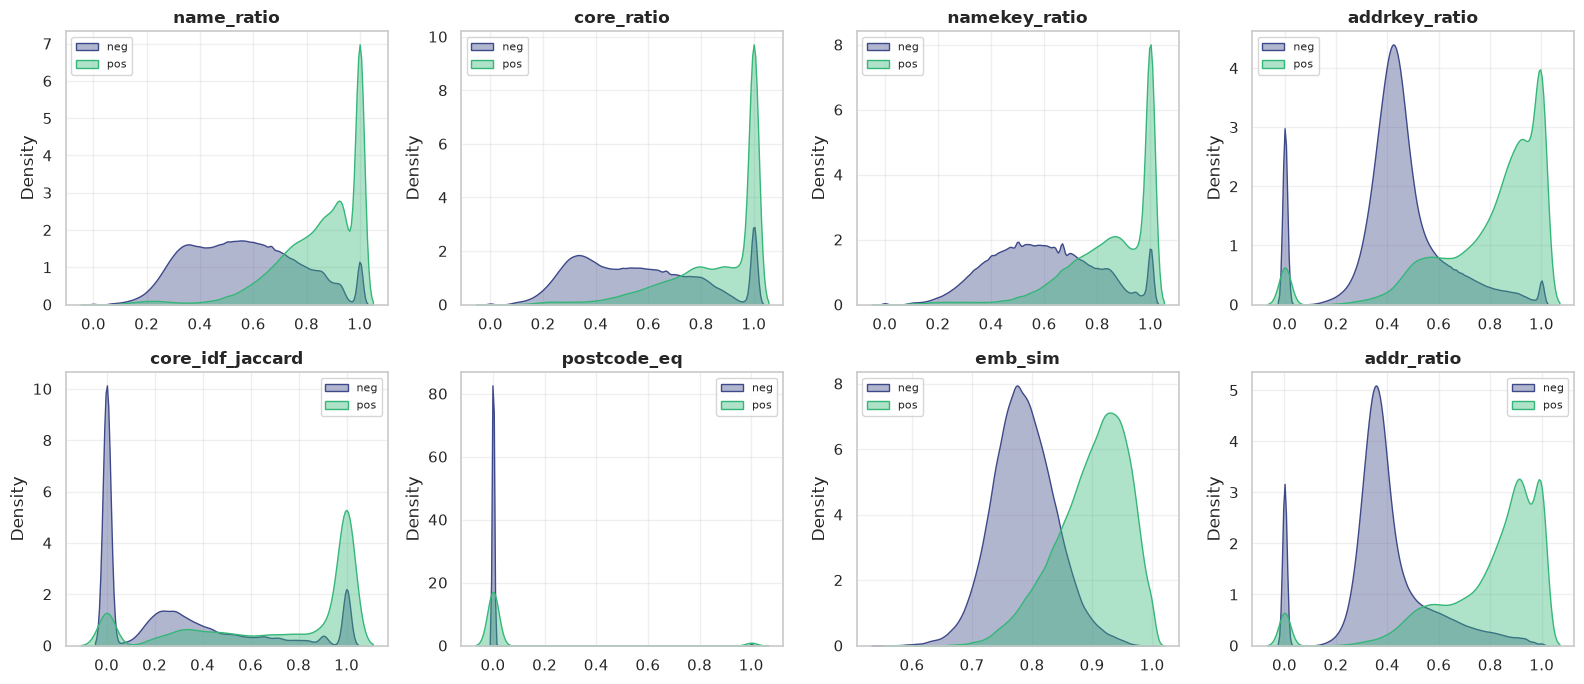

In [21]:
if need(WORK / 'train_feats_0.parquet', 'python -m ber.run features:train'):
    n_total = pl.scan_parquet(WORK / 'train_feats_*.parquet').select(pl.len()).collect().item()  # metadata only
    # one of 8 S1-hash chunks, then a further 1/10 S1 hash-sample (keeps whole candidate sets)
    feats_sample = (pl.scan_parquet(WORK / 'train_feats_0.parquet')
                      .filter(pl.col('s1_idx').hash(0) % 10 == 0).collect())
    print('train_feats rows (all chunks):', n_total, '| sampled:', feats_sample.height)

    res_ = json.loads((WORK / 'train_result.json').read_text()) if (WORK / 'train_result.json').exists() else {}
    cand_feats = ['name_ratio', 'core_ratio', 'namekey_ratio', 'addrkey_ratio',
                  'core_idf_jaccard', 'postcode_eq', 'emb_sim', 'addr_ratio']
    top_feats = [f for f in cand_feats if f in feats_sample.columns][:8]
    if len(top_feats) < 8:  # fall back to other stage-1 features present
        extra = [f for f in res_.get('features', []) if f in feats_sample.columns and f not in top_feats]
        top_feats += extra[:8 - len(top_feats)]
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax, f in zip(axes.flat, top_feats):
        pos = feats_sample.filter(pl.col('label') == 1)[f].drop_nulls().to_numpy()
        neg = feats_sample.filter(pl.col('label') == 0)[f].drop_nulls().to_numpy()
        sns.kdeplot(neg, ax=ax, color=PALETTE[1], label='neg', fill=True, alpha=0.4)
        sns.kdeplot(pos, ax=ax, color=PALETTE[5], label='pos', fill=True, alpha=0.4)
        ax.legend(fontsize=8)
        style_ax(ax, title=f)
    plt.tight_layout()
    plt.show()

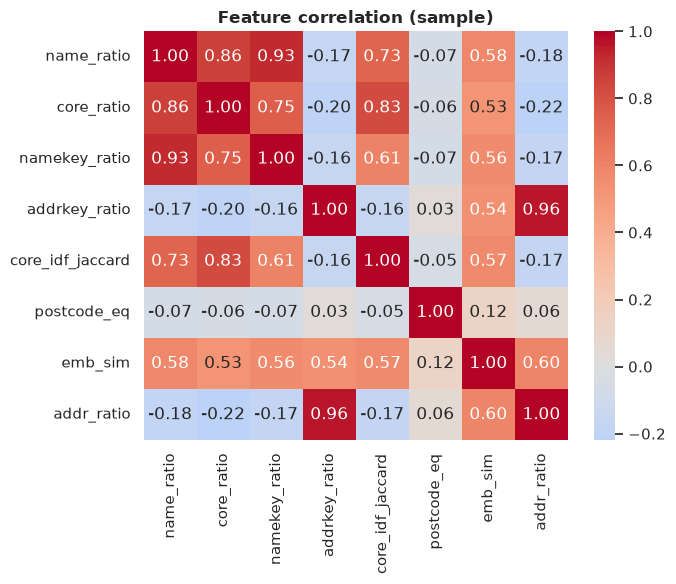

In [22]:
if (WORK / 'train_feats_0.parquet').exists():
    num_cols = [c for c in top_feats if c in feats_sample.columns]
    corr = feats_sample.select(num_cols).to_pandas().corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', ax=ax)
    style_ax(ax, title='Feature correlation (sample)')
    plt.tight_layout()
    plt.show()

## 6. Model — two-stage LightGBM + cross-encoder + 1-to-1 assignment

- **Stage 1**: LightGBM on the ~100 pair features; two OOF halves of the `tr` fold, each fit on 350k S1
  (~44M rows) and early-stopped on val; every pair is predicted by a model that did not see its S1 (`p1`).
- **Cross-encoder** scores pairs with `p1 >= 0.005` (`ce`).
- **Stage 2**: LightGBM on pairs with `p1 >= 0.001` using `p1`, `ce`, anchor features and `p` competition
  ranks -> `p`.
- **Assignment** (`ber.model.assign`): 1-to-1 argmax (best S1 per `c_idx`) over **all** S1, then keep
  `p >= t` and `p >= alpha * max_p_for_that_s1`; `ber.model.tune` grid-searches `(t, alpha)` -> `t=0.425, alpha=0.7`.

**Validation progression** (same 100k val S1; v4 validation is stricter: val S1 compete with all train S1):

| approach | val macro F0.5 |
|---|---|
| empty prediction | ~0.056 |
| earlier attempt | 0.29 |
| v1 | 0.9612 |
| v2 | 0.9743 |
| v2 + cross-encoder (base) | 0.9815 |
| v3 | 0.9836 |
| v4 stage 1 only | 0.9784 |
| **v4 final (stage 2)** | **0.9862** (India 0.9823, US 0.9887) |

Ceiling imposed by blocking recall: ~0.9935.

val_f05: 0.9861643723048787 | best t: 0.42499999999999993 | best alpha: 0.7 | stage1 val_f05: 0.9784289073619036


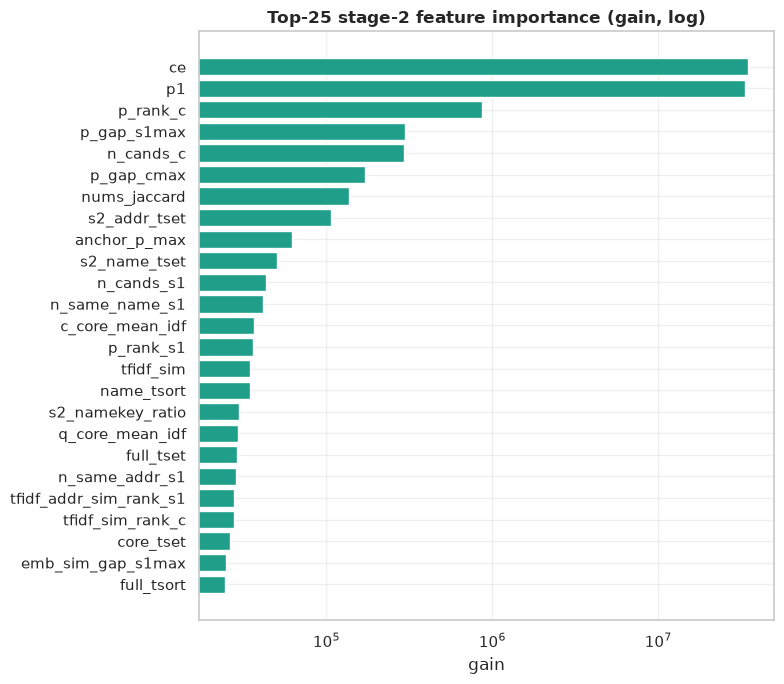

In [23]:
result_path = WORK / 'train_result.json'
if need(result_path, 'python -m ber.run train'):
    res = json.loads(result_path.read_text())
    print('val_f05:', res['val_f05'], '| best t:', res['t'], '| best alpha:', res['alpha'],
          '| stage1 val_f05:', res['stage1']['val_f05'])

    imp = list(res['importance'].items())[:25]
    fig, ax = plt.subplots(figsize=(8, 7))
    names_, gains_ = zip(*imp[::-1])
    ax.barh(names_, gains_, color=PALETTE[4])
    ax.set_xscale('log')
    style_ax(ax, title='Top-25 stage-2 feature importance (gain, log)', xlabel='gain')
    plt.tight_layout()
    plt.show()

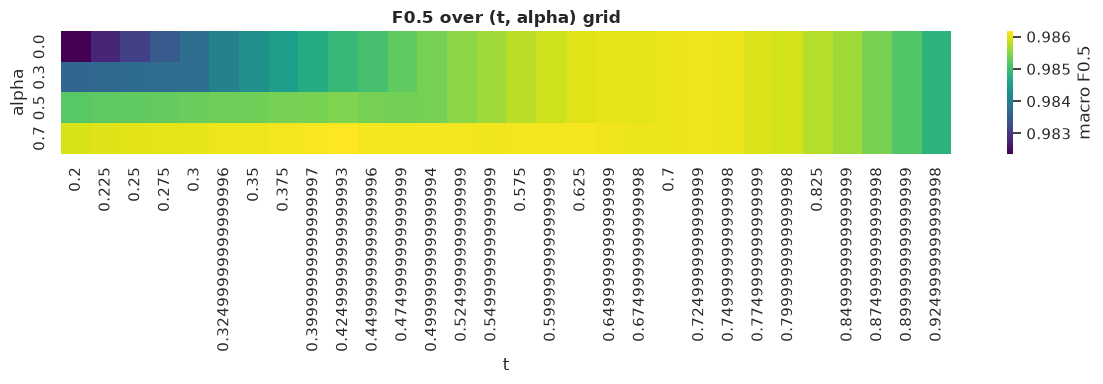

In [24]:
tune_path = WORK / 'tune_table.csv'
if need(tune_path, 'python -m ber.run train  (writes tune_table.csv)'):
    tt = pl.read_csv(tune_path)
    piv = tt.pivot(index='alpha', on='t', values='score').to_pandas().set_index('alpha')
    fig, ax = plt.subplots(figsize=(12, 4))
    sns.heatmap(piv, cmap='viridis', ax=ax, cbar_kws={'label': 'macro F0.5'})
    style_ax(ax, title='F0.5 over (t, alpha) grid', xlabel='t', ylabel='alpha')
    plt.tight_layout()
    plt.show()

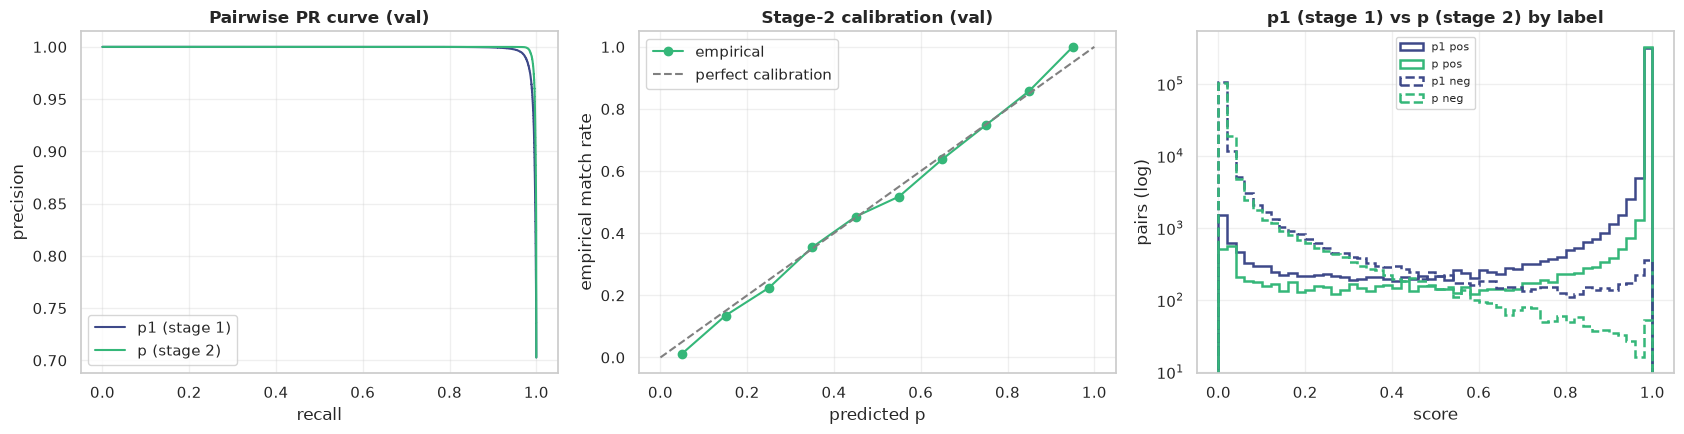

In [25]:
val_pred_path = WORK / 'val_pred.parquet'
if need(val_pred_path, 'python -m ber.run train  (writes val_pred.parquet: s1_idx,c_idx,p1,p,label)'):
    vp = pl.read_parquet(val_pred_path)
    y = vp['label'].to_numpy()
    from sklearn.metrics import precision_recall_curve
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for col, color, nm in (('p1', PALETTE[1], 'p1 (stage 1)'), ('p', PALETTE[5], 'p (stage 2)')):
        prec, rec, _ = precision_recall_curve(y, vp[col].to_numpy())
        axes[0].plot(rec, prec, color=color, label=nm)
    axes[0].legend()
    style_ax(axes[0], title='Pairwise PR curve (val)', xlabel='recall', ylabel='precision')

    p = vp['p'].to_numpy()
    bins = np.linspace(0, 1, 11)
    bin_idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
    emp_rate = [y[bin_idx == i].mean() if (bin_idx == i).any() else np.nan for i in range(10)]
    axes[1].plot(bins[:-1] + 0.05, emp_rate, marker='o', color=PALETTE[5], label='empirical')
    axes[1].plot([0, 1], [0, 1], '--', color='gray', label='perfect calibration')
    axes[1].legend()
    style_ax(axes[1], title='Stage-2 calibration (val)', xlabel='predicted p', ylabel='empirical match rate')

    # stage-1 p1 vs stage-2 p score distributions, positives vs negatives
    for lab, name, ls in ((1, 'pos', '-'), (0, 'neg', '--')):
        sub_ = vp.filter(pl.col('label') == lab)
        for col, color in (('p1', PALETTE[1]), ('p', PALETTE[5])):
            axes[2].hist(sub_[col].to_numpy(), bins=50, range=(0, 1), histtype='step', lw=1.8, ls=ls,
                         color=color, label=f'{col} {name}')
    axes[2].legend(fontsize=8)
    style_ax(axes[2], title='p1 (stage 1) vs p (stage 2) by label', xlabel='score', ylabel='pairs (log)', logy=True)
    plt.tight_layout()
    plt.show()

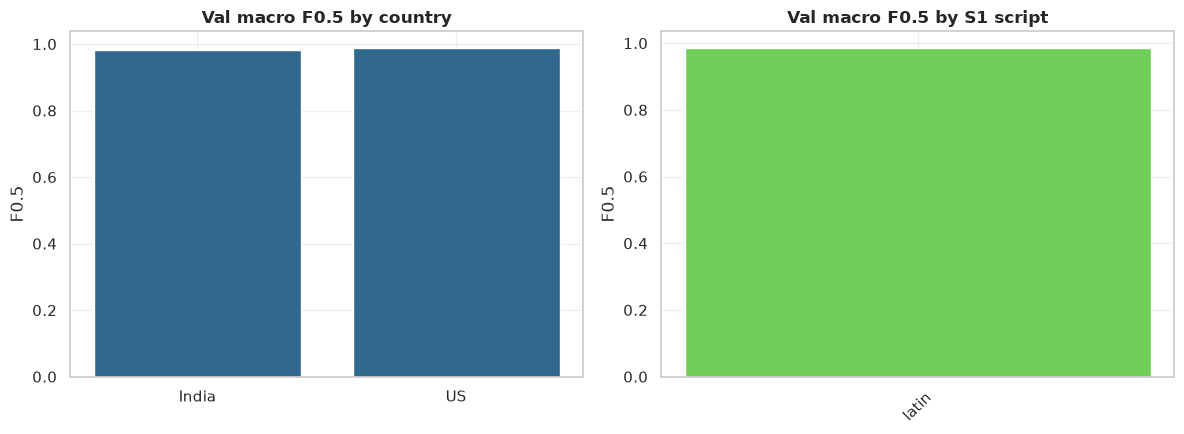

In [26]:
if result_path.exists():
    by_country = pl.DataFrame(res['by_country'])
    by_script = pl.DataFrame(res['by_script'])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].bar(by_country['group'], by_country['macro_f05'], color=PALETTE[2])
    style_ax(axes[0], title='Val macro F0.5 by country', ylabel='F0.5')
    axes[1].bar(by_script['group'], by_script['macro_f05'], color=PALETTE[6])
    style_ax(axes[1], title='Val macro F0.5 by S1 script', ylabel='F0.5')
    axes[1].tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

In [27]:
# progression on the SAME 100k val S1 (v4 validation is stricter: val S1 compete with all train S1)
comparison = pl.DataFrame({
    'approach': ['empty prediction', 'earlier attempt', 'v1', 'v2', 'v2 + CE (base)', 'v3',
                 'v4 stage 1', 'v4 final (stage 2)'],
    'macro_f05': [0.056, 0.29, 0.9612, 0.9743, 0.9815, 0.9836, 0.9784,
                  res['val_f05'] if result_path.exists() else 0.9862],
})
comparison

approach,macro_f05
str,f64
"""empty prediction""",0.056
"""earlier attempt""",0.29
"""v1""",0.9612
"""v2""",0.9743
"""v2 + CE (base)""",0.9815
"""v3""",0.9836
"""v4 stage 1""",0.9784
"""v4 final (stage 2)""",0.986164


## 7. Error analysis

Top false positives / false negatives from validation predictions (stage-2 `p`), with names and
addresses side by side, and a rough failure-bucket breakdown (cross-script, missing address).
Read the printed tables below for the dominant failure modes of the current run.

In [28]:
if val_pred_path.exists() and (WORK / 'train_prep.parquet').exists():
    prep_train_full = pl.read_parquet(WORK / 'train_prep.parquet').select(
        'idx', 'entity_id', 'name_orig', 'addr_orig', 'script')  # prep lives in WORK (v4)
    vp_named = (vp.join(prep_train_full.rename(lambda c: 's1_' + c if c != 'idx' else 's1_idx'), on='s1_idx')
                  .join(prep_train_full.rename(lambda c: 'c_' + c if c != 'idx' else 'c_idx'), on='c_idx'))

    fp = vp_named.filter((pl.col('label') == 0)).sort('p', descending=True).head(15)
    fn = vp_named.filter((pl.col('label') == 1)).sort('p').head(15)
    print('--- top false positives (high p, wrong) ---')
    display(fp.select('s1_name_orig', 'c_name_orig', 's1_addr_orig', 'c_addr_orig', 'p'))
    print('--- top false negatives (low p, actually true) ---')
    display(fn.select('s1_name_orig', 'c_name_orig', 's1_addr_orig', 'c_addr_orig', 'p'))

    buckets = vp_named.filter(pl.col('label') == 1).with_columns(
        (pl.col('s1_script') != pl.col('c_script')).alias('cross_script'),
        (pl.col('s1_addr_orig') == '').alias('s1_addr_missing'),
        (pl.col('c_addr_orig') == '').alias('c_addr_missing'),
    )
    print('cross-script share among FN (p<0.5):',
          buckets.filter(pl.col('p') < 0.5)['cross_script'].mean())
else:
    print('[missing] val_pred.parquet / train_prep.parquet -> run: ber.run train (+ prep already required for train)')

--- top false positives (high p, wrong) ---


s1_name_orig,c_name_orig,s1_addr_orig,c_addr_orig,p
str,str,str,str,f64
"""ql pacific east l.l.c.""","""ql pacific east l.l.c.""","""4112 brody crossing, benton, a…","""412 brody crossing, benton, ar""",0.99994
"""roos & thompson clinic""","""inc. roos & thompson clinic""","""23289 aberdeen court, foley, a…","""23289 aberdeen court, n/a, fol…",0.999931
"""temple presbyterian church""","""temple presbyterian church inc""","""1505 estate lane, lake forest,…","""1505 estate lane, il, lake for…",0.999852
"""yamuna ventures""","""yamuna ventures llp""","""1flat no 302, hno. 5-9-13, 3rd…","""1flat no 302, hno. 5-9-13, 3rd…",0.999822
"""cws paloma""","""cws paloma corp""","""4262 college avenue, corning, …","""4262 college ave, corning, new…",0.99975
…,…,…,…,…
"""zrk media ltd""","""zrkmedia.com""","""6th floor, shree ram trade cen…","""mumbai, महाराष्ट्र, mumbai cit…",0.998354
"""a cure 7 it""","""7 cure a ik""","""3232 grandview street, springf…","""003232 grandview st, springfie…",0.998146
"""blue healthcare limited""","""m/s blue healthcare limited li…","""15, shree ram nagar, building …","""15, mumbai, null, महाराष्ट्र""",0.997671


--- top false negatives (low p, actually true) ---


s1_name_orig,c_name_orig,s1_addr_orig,c_addr_orig,p
str,str,str,str,f64
"""jarlay environmental of rensse…","""jarlay 0f rensselaer (center)""","""751 matheson avenue, rensselae…","""in, 1028 matheson avenue, rens…",0.000275
"""bright bike shop""","""bright shop bíke""","""2024 kings lane, cynthiana, ky""","""""",0.000431
"""penrod fund vi""","""penrod fund vi (council) | www…","""6622 bonniewood drive, wa, fl …","""662 bonniewood drive, fl. 1, t…",0.000961
"""red tavern""","""red tavem tavem""","""13507 woodvale court, prince w…","""63507 woodvale court, prince w…",0.001067
"""ear nose & throat empire partn…","""ear nose throat empire partner…","""2309 leland ridge walk, fl 0, …","""missouri, saint louis, 2308 le…",0.001283
…,…,…,…,…
"""nasdaq""","""nasdaq llc""","""3512 stoney creek church road,…","""nc, 3525 stoney creek church r…",0.002569
"""pc capital""","""pc-5ervice""","""lower ground flooor c-4/5, saf…","""lwoer ground flooor c-/5, dl, …",0.002696
"""cozy bike shop l.l.c.""","""cozy bike l.l.c. shop""","""9908 jocund drive, manor, tx""","""""",0.002741


cross-script share among FN (p<0.5): 0.004719004719004719


## 8. Test inference & submission

Test stages: `features:test` -> `predict1:test` (stage-1 `p1` on every pair) -> `cescore:test`
(cross-encoder on `p1 >= 0.005`) -> `predict:test` (stage 2, `assign` with the tuned `t=0.425, alpha=0.7`,
`write_submission` -> `matching_results.tsv` / `candidate_pairs.tsv`). `ber.model.validate` checks the
submission's structure (header, 1-to-1 no-dup-id, ids from the candidate pool, matches within candidates).
Results (v4): France 245,064 S1 matched / 848,775 pairs; US 624,928 / 2,239,780; India 760,815 / 2,660,032;
validator PASS.

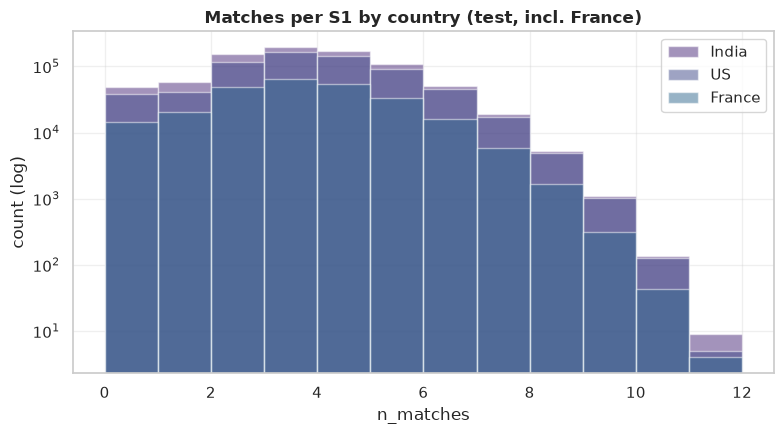

In [29]:
sub_path = OUT / 'matching_results.tsv'
if need(sub_path, 'python -m ber.run predict:test'):
    sub = pl.read_csv(sub_path, separator='\t', quote_char=None, infer_schema=False,
                       empty_string_is_null=False)
    sub_counts = sub.with_columns(
        pl.when(pl.col('matched_entity_ids') == '').then(0)
          .otherwise(pl.col('matched_entity_ids').str.split(',').list.len())
          .alias('n_matches')
    )
    test_prep_path = WORK / 'test_prep.parquet'
    if test_prep_path.exists():
        test_country = (pl.read_parquet(test_prep_path)
                          .filter(pl.col('src') == 1)
                          .select(pl.col('entity_id').alias('source1_entity_id'), 'country'))
        sub_counts = sub_counts.join(test_country, on='source1_entity_id', how='left')
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for i, c in enumerate(sub_counts['country'].unique().to_list()):
            vals = sub_counts.filter(pl.col('country') == c)['n_matches'].to_list()
            ax.hist(vals, bins=range(0, max(vals) + 2), alpha=0.5, label=c, color=PALETTE[i % len(PALETTE)])
        ax.legend()
        style_ax(ax, title='Matches per S1 by country (test, incl. France)', xlabel='n_matches', ylabel='count (log)', logy=True)
        plt.tight_layout()
        plt.show()
    else:
        print('n_matches distribution (country unavailable — test_prep.parquet missing):')
        print(sub_counts['n_matches'].value_counts().sort('n_matches'))

In [30]:
cand_path = OUT / 'candidate_pairs.tsv'
if sub_path.exists() and cand_path.exists() and (WORK / 'test_prep.parquet').exists():
    test_prep = pl.read_parquet(WORK / 'test_prep.parquet')
    s1_ids = set(test_prep.filter(pl.col('src') == 1)['entity_id'].to_list())
    pool_ids = set(test_prep.filter(pl.col('src') != 1)['entity_id'].to_list())
    issues = bm.validate(str(sub_path), str(cand_path), s1_ids, pool_ids)
    print('VALIDATION:', 'PASS' if not issues else issues[:20])
else:
    print('[missing] output/matching_results.tsv, output/candidate_pairs.tsv or working/test_prep.parquet -> run: python -m ber.run predict:test')

VALIDATION: PASS


## 9. Conclusions

- **Result.** v4 validation macro F0.5 = **0.9862** (t=0.425, alpha=0.7; India 0.9823, US 0.9887) vs.
  ~0.056 for an empty prediction and 0.29 for the earlier attempt; stage 1 alone is 0.9784, so the
  cross-encoder + anchor + competition-rank stage 2 adds ~0.008. Validation is stricter than earlier
  versions (val S1 compete with all train S1). The ceiling from blocking recall is ~0.9935.
- **Blocking.** Six kNN methods (+ key joins) per country reach union recall ~0.983 on val S1; the hybrid
  cap (learned stage-0 top-60 U each method's top-10 U key hits) keeps recall 0.9803 at ~127 candidates/S1.
  Blocking *all* 2.2M train S1 removed a train/test skew in pool-side competition features.
- **Text.** Two views, Indic transliteration with anusvara/schwa handling, leet de-noising, web-junk
  stripping, leading-zero number normalization, and three phonetic keys (skeleton, coarse voicing-blind,
  sorted) address the multilingual noise; `country` is excluded from features for the unseen-France shift.
- **Test.** France 245,064 / 848,775 S1 matched / pairs, US 624,928 / 2,239,780, India 760,815 / 2,660,032 of
  1,732,544 test S1; submission validator PASS.

**Possible next steps.** France pseudo-labels (self-training on high-confidence mutual-top1 France
predictions); per-country tuning of `key_block`'s `max_group` and TF-IDF `max_df`; the remaining loss is
mostly the ~1.7% blocking-recall gap plus hard near-duplicate negatives.